# 📊 Analyse univariée et bivariée

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 10h00** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Nettoyer le minimum avant d'analyser, en le justifiant
- Décrire les variables clés une par une
- Tester vos hypothèses sur le lien entre deux variables

In [1]:
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")

✅ Configuration prête : chaque fichier de données se télécharge au premier usage


In [2]:
# Secteur traité : Crédit Azur (banque) — autres choix : "commerce", "hotellerie"
SECTEUR = "banque"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Crédit Azur · 20477 lignes, 20 colonnes


In [3]:
from scipy import stats

## 1. Le nettoyage minimal
Retirez les doublons exacts, les âges inférieurs à 18 ans et les montants négatifs. Combien de lignes perdez-vous ?

In [4]:
# Doublons exacts, âges < 18 ans et montants négatifs retirés (fonction du cours)
df = nettoyage_minimal(brut, cfg)
print(len(brut), "→", len(df), f"({len(brut) - len(df)} lignes perdues, {1 - len(df) / len(brut):.2%})")

# Détail de ce qui est retiré (par étape)
dup = brut.duplicated().sum()
sans_dup = brut.drop_duplicates()
mineurs = (sans_dup["age"] < 18).sum()
negatifs = (sans_dup[cfg["ca"]] < 0).sum()
print(f"doublons exacts : {dup} · âges < 18 ans : {mineurs} · montants négatifs : {negatifs}")

20477 → 20384 (93 lignes perdues, 0.45%)
doublons exacts : 82 · âges < 18 ans : 11 · montants négatifs : 0


**Justification** (cellule à garder dans le livrable) : on retire 93 lignes sur 20 477 (0,45 %), ce qui ne peut pas changer les conclusions.
- **82 doublons exacts** : même `demande_id` et mêmes valeurs, donc une double saisie, pas deux demandes.
- **11 demandes d'âge 17 ans** : hors du périmètre d'un crédit à la consommation (mineurs).
- **0 montant négatif** dans ce jeu de données (la règle reste appliquée par précaution).
- **Conservés volontairement** : les refusés (PNB = 0), car la décision est précisément l'objet de l'étude ; les 2,8 % de revenus manquants, car ils semblent aléatoires (identiques d'un canal à l'autre) et la variable n'entre pas dans les premières analyses ; on les écartera seulement dans le modèle de la section biais.

## 2. La variable de chiffre d'affaires
Statistiques descriptives, histogramme (échelle log si besoin) et boîte à moustaches. La moyenne représente-t-elle bien un client typique ?

count    20384.0
mean       522.4
std        674.2
min          0.0
25%          0.0
50%        236.2
75%        883.8
max       9082.5

Demandes à PNB nul (crédit refusé) : 36.0%
Asymétrie : 1.69 (toutes demandes) · 1.40 (PNB > 0)
Crédits accordés : moyenne 817 € · médiane 672 € · écart moyenne/médiane +22%
Quantiles (PNB > 0) : {0.1: 74.0, 0.25: 273.0, 0.5: 672.0, 0.75: 1190.0, 0.9: 1715.0, 0.99: 3007.0}


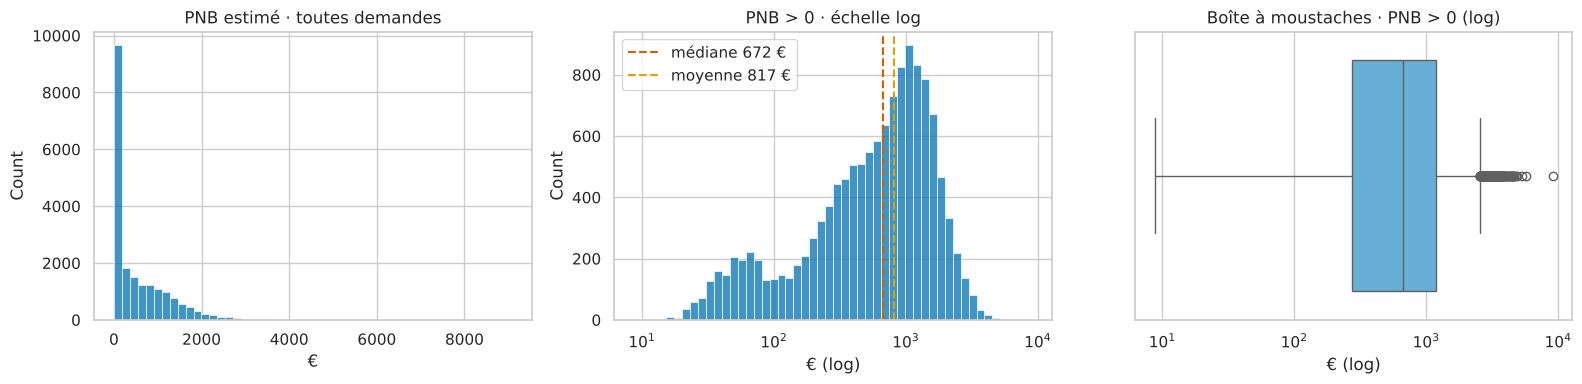

In [5]:
from config_projet import PALETTE
ca = df[cfg["ca"]]
pos = ca[ca > 0]                      # PNB > 0 : uniquement les crédits accordés

print(ca.describe().round(1).to_string())
print(f"\nDemandes à PNB nul (crédit refusé) : {(ca == 0).mean():.1%}")
print(f"Asymétrie : {ca.skew():.2f} (toutes demandes) · {pos.skew():.2f} (PNB > 0)")
print(f"Crédits accordés : moyenne {pos.mean():,.0f} € · médiane {pos.median():,.0f} € "
      f"· écart moyenne/médiane {pos.mean() / pos.median() - 1:+.0%}")
print("Quantiles (PNB > 0) :", pos.quantile([.1, .25, .5, .75, .9, .99]).round(0).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(ca, bins=50, ax=axes[0], color=PALETTE[0])
axes[0].set_title("PNB estimé · toutes demandes"); axes[0].set_xlabel("€")
sns.histplot(pos, bins=50, log_scale=True, ax=axes[1], color=PALETTE[0])
axes[1].axvline(pos.median(), color=PALETTE[5], ls="--", label=f"médiane {pos.median():,.0f} €")
axes[1].axvline(pos.mean(), color=PALETTE[1], ls="--", label=f"moyenne {pos.mean():,.0f} €")
axes[1].legend(); axes[1].set_title("PNB > 0 · échelle log"); axes[1].set_xlabel("€ (log)")
sns.boxplot(x=pos, ax=axes[2], color=PALETTE[4]); axes[2].set_xscale("log")
axes[2].set_title("Boîte à moustaches · PNB > 0 (log)"); axes[2].set_xlabel("€ (log)")
plt.tight_layout(); plt.show()

## 3. Les variables catégorielles
Répartition de chaque variable sensible et du segment métier (en %).

--- tranche_age (% des demandes)
tranche_age
25-34    26.0
35-44    25.6
45-54    19.6
55-64    12.9
18-24     8.8
65+       7.0 

--- genre (% des demandes)
genre
H    57.2
F    42.8 

--- region (% des demandes)
region
Nord-Est         23.2
Sud-Est          22.1
Ouest            21.2
Île-de-France    18.6
Sud-Ouest        13.9
Outre-mer         1.0 

--- type_credit (% des demandes)
type_credit
personnel       30.0
auto            29.8
travaux         25.2
renouvelable    14.9 



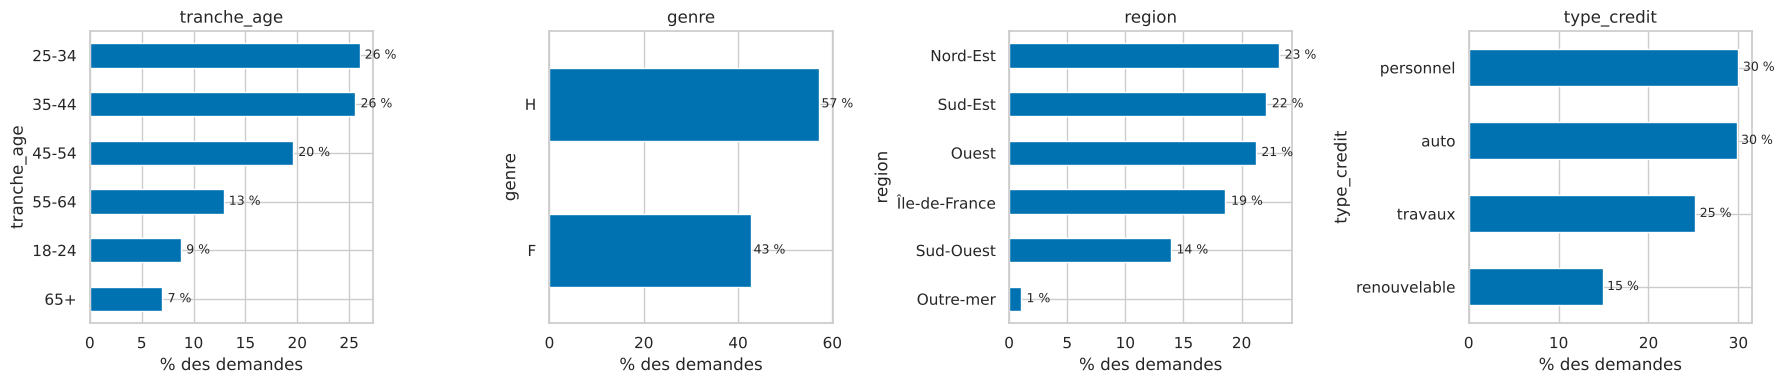

In [6]:
cols = cfg["sensibles"] + [cfg["segment"]]
fig, axes = plt.subplots(1, len(cols), figsize=(4.5 * len(cols), 4))
for ax, col in zip(axes, cols):
    part = df[col].fillna("inconnu").value_counts(normalize=True).mul(100).round(1)
    print(f"--- {col} (% des demandes)"); print(part.to_string(), "\n")
    part.sort_values().plot.barh(ax=ax, color=PALETTE[0])
    ax.set_title(col); ax.set_xlabel("% des demandes")
    for i, v in enumerate(part.sort_values()):
        ax.text(v + 0.5, i, f"{v:.0f} %", va="center", fontsize=9)
plt.tight_layout(); plt.show()

## 4. Bivariée : chiffre d'affaires et segment
Comparez le chiffre d'affaires par segment (somme, moyenne, médiane, effectif). La différence est-elle significative ? Utilisez Kruskal-Wallis.

,somme,moyenne,mediane,effectif,part_du_PNB_%,mediane_si_accord,taux_accord_%
type_credit,,,,,,,
auto,5123758.5,842.4,826.0,6082,48.1,1239.0,61.3
travaux,3813293.8,742.0,735.0,5139,35.8,1015.0,65.9
personnel,1573481.0,257.2,238.0,6117,14.8,346.5,64.9
renouvelable,138027.8,45.3,40.2,3046,1.3,59.5,64.2


KruskalResult(statistic=np.float64(2472.6860750992205), pvalue=np.float64(0.0))
taille d'effet ε² = 0.121  (0,01 faible · 0,06 moyen · 0,14 fort)


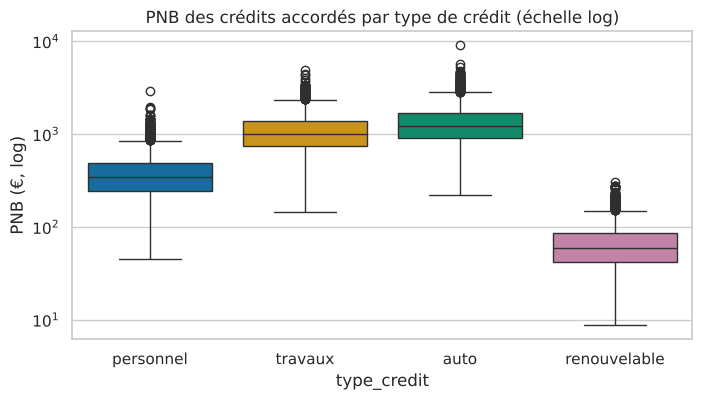

In [7]:
seg, ca_col = cfg["segment"], cfg["ca"]
par_segment = df.groupby(seg)[ca_col].agg(somme="sum", moyenne="mean", mediane="median", effectif="count").round(1)
par_segment["part_du_PNB_%"] = (100 * par_segment["somme"] / par_segment["somme"].sum()).round(1)
par_segment["mediane_si_accord"] = df[df[ca_col] > 0].groupby(seg)[ca_col].median().round(1)
par_segment["taux_accord_%"] = (100 * df.groupby(seg)[cfg["decision"]].mean()).round(1)
display(par_segment.sort_values("somme", ascending=False))

groupes = [g[ca_col].values for _, g in df.groupby(seg)]
print(stats.kruskal(*groupes))
H, p = stats.kruskal(*groupes)
n, k = len(df), len(groupes)
eps2 = (H - k + 1) / (n - k)      # taille d'effet (epsilon² de Kruskal-Wallis)
print(f"taille d'effet ε² = {eps2:.3f}  (0,01 faible · 0,06 moyen · 0,14 fort)")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df[df[ca_col] > 0], x=seg, y=ca_col, ax=ax, palette=PALETTE[:k], hue=seg, legend=False)
ax.set_yscale("log"); ax.set_title("PNB des crédits accordés par type de crédit (échelle log)")
ax.set_ylabel("PNB (€, log)"); plt.show()

## 5. Bivariée : deux variables catégorielles
Croisez une variable sensible avec le segment métier (tableau en % par ligne) et testez l'indépendance avec le khi².

type_credit,auto,personnel,renouvelable,travaux
tranche_age,,,,
18-24,30.0,30.0,14.3,25.7
25-34,29.6,30.3,14.5,25.7
35-44,30.5,30.0,14.7,24.8
45-54,29.9,29.6,16.0,24.5
55-64,29.1,30.6,14.3,25.9
65+,29.5,28.9,16.4,25.2


khi² = 12.3 · ddl = 15 · p = 6.57e-01 · V de Cramér = 0.014


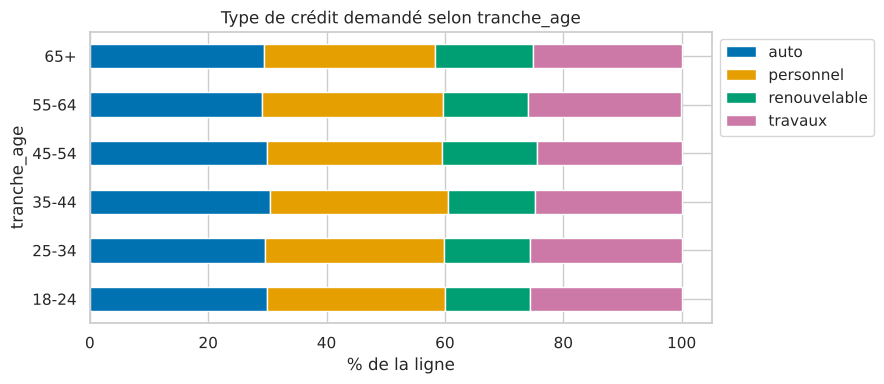

In [8]:
var = cfg["sensibles"][0]
tab = pd.crosstab(df[var], df[cfg["segment"]], normalize="index").mul(100).round(1)
display(tab)
chi2, p, dof, attendu = stats.chi2_contingency(pd.crosstab(df[var], df[cfg["segment"]]))
n = len(df); k = min(pd.crosstab(df[var], df[cfg["segment"]]).shape) - 1
print(f"khi² = {chi2:.1f} · ddl = {dof} · p = {p:.2e} · V de Cramér = {np.sqrt(chi2 / (n * k)):.3f}")

if var == "tranche_age":
    tab = tab.loc[["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]]
tab.plot.barh(stacked=True, figsize=(9, 4), color=PALETTE[:tab.shape[1]])
plt.xlabel("% de la ligne"); plt.title(f"Type de crédit demandé selon {var}")
plt.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

## 6. Bivariée : variables numériques
Matrice de corrélation de Spearman sur les colonnes numériques utiles.

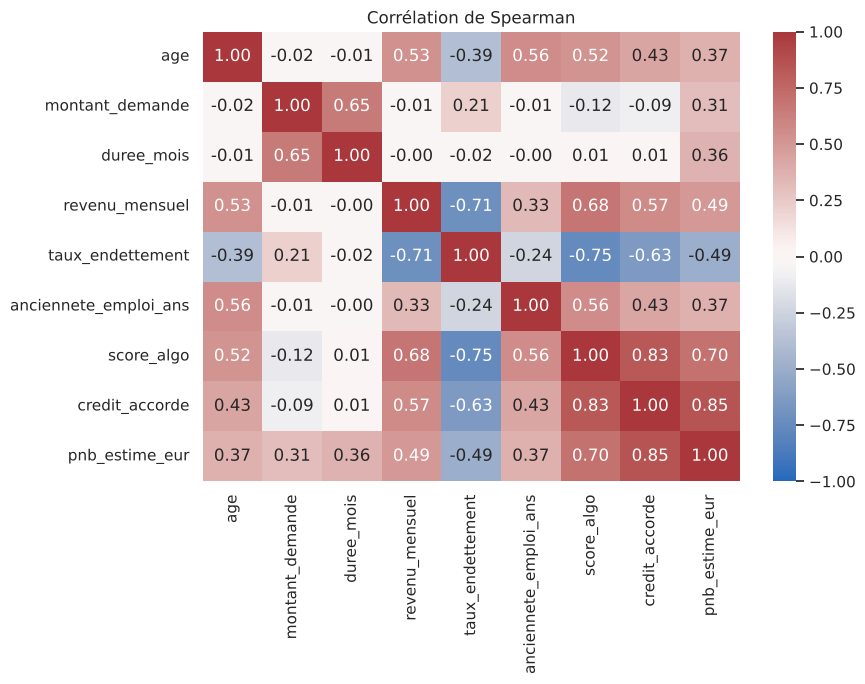

Liaisons fortes (|rho| > 0,5) :
credit_accorde         pnb_estime_eur           0.85
score_algo             credit_accorde           0.83
taux_endettement       score_algo              -0.75
revenu_mensuel         taux_endettement        -0.71
score_algo             pnb_estime_eur           0.70
revenu_mensuel         score_algo               0.68
montant_demande        duree_mois               0.65
taux_endettement       credit_accorde          -0.63
revenu_mensuel         credit_accorde           0.57
age                    anciennete_emploi_ans    0.56
anciennete_emploi_ans  score_algo               0.56
age                    revenu_mensuel           0.53
                       score_algo               0.52

Liaisons avec la décision :
pnb_estime_eur           0.85
score_algo               0.83
taux_endettement        -0.63
revenu_mensuel           0.57
age                      0.43
anciennete_emploi_ans    0.43
montant_demande         -0.09
duree_mois               0.01


In [9]:
num = df.select_dtypes("number").drop(columns=["rembourse_sans_incident", "montant_accorde"], errors="ignore")
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélation de Spearman"); plt.tight_layout(); plt.show()

paires = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().rename("rho")
print("Liaisons fortes (|rho| > 0,5) :"); print(paires[paires.abs() > 0.5].sort_values(key=abs, ascending=False).round(2).to_string())
print("\nLiaisons avec la décision :"); print(corr["credit_accorde"].drop("credit_accorde").sort_values(key=abs, ascending=False).round(2).to_string())

## 7. Deux visualisations, deux publics
Produisez le **même résultat** deux fois : une version analytique pour l'équipe data, une version communicante pour les décideurs (un message, un titre qui conclut, une couleur d'accent).

,sum,size,taux,bas,haut
tranche_age,,,,,
18-24,327,1788,0.183,0.166,0.201
25-34,2332,5299,0.440,0.427,0.453
35-44,3600,5228,0.689,0.676,0.701
45-54,3316,4002,0.829,0.817,0.840
55-64,2301,2636,0.873,0.860,0.885
65+,1164,1431,0.813,0.792,0.833


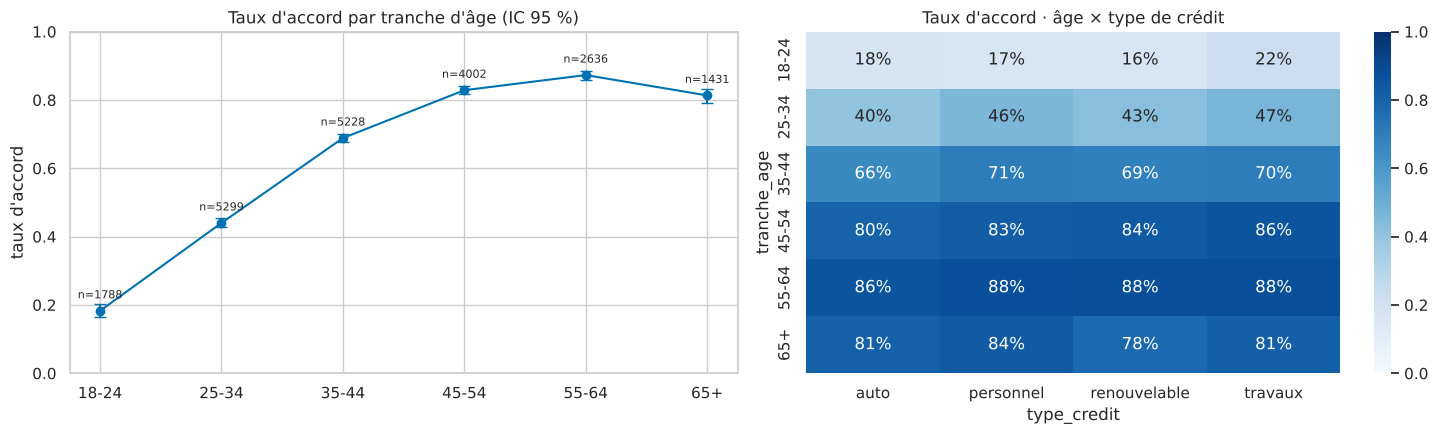

In [10]:
# Version équipe data : taux d'accord par tranche d'âge, intervalle de confiance et croisement avec le type de crédit
from statsmodels.stats.proportion import proportion_confint
ordre = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
g = df.groupby("tranche_age")["credit_accorde"].agg(["sum", "size"]).loc[ordre]
g["taux"] = g["sum"] / g["size"]
g["bas"], g["haut"] = proportion_confint(g["sum"], g["size"], method="wilson")
display(g.assign(taux=g["taux"].round(3), bas=g["bas"].round(3), haut=g["haut"].round(3)))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].errorbar(ordre, g["taux"], yerr=[g["taux"] - g["bas"], g["haut"] - g["taux"]], fmt="o-", color=PALETTE[0], capsize=4)
for x, (t, n_) in zip(ordre, zip(g["taux"], g["size"])):
    axes[0].annotate(f"n={n_}", (x, t), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8)
axes[0].set_ylim(0, 1); axes[0].set_title("Taux d'accord par tranche d'âge (IC 95 %)"); axes[0].set_ylabel("taux d'accord")
croise = df.pivot_table(index="tranche_age", columns=cfg["segment"], values="credit_accorde", aggfunc="mean").loc[ordre]
sns.heatmap(croise, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Taux d'accord · âge × type de crédit")
plt.tight_layout(); plt.show()

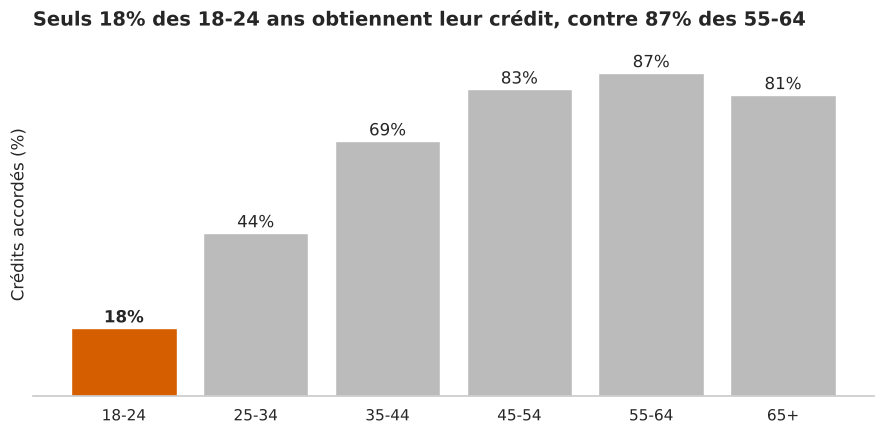

In [11]:
# Version décideurs : un message, une couleur d'accent, le reste en gris
taux = df.groupby("tranche_age")["credit_accorde"].mean().loc[["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]]
pire, meilleur = taux.idxmin(), taux.idxmax()
couleurs = [PALETTE[5] if a == pire else "#BBBBBB" for a in taux.index]
fig, ax = plt.subplots(figsize=(9, 4.5))
barres = ax.bar(taux.index, taux.values * 100, color=couleurs)
for b, v in zip(barres, taux.values):
    ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=12,
            fontweight="bold" if v == taux.min() else "normal")
ax.set_title(f"Seuls {taux[pire]:.0%} des 18-24 ans obtiennent leur crédit, contre {taux[meilleur]:.0%} des {meilleur}",
             loc="left", fontsize=14, fontweight="bold")
ax.set_ylabel("Crédits accordés (%)"); ax.set_yticks([])
ax.grid(False); ax.set_ylim(0, taux.max() * 100 * 1.12)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Vos hypothèses après cette étape**
- **H1 (chute du taux d'accord avec le score V2) : à vérifier dans le temps** (notebook 03). Ici, le taux d'accord est comparable entre types de crédit (61 à 66 %), la baisse n'est donc pas propre à un produit.
- **H2 (les jeunes sont les plus touchés) : confirmée.** Taux d'accord de 18 % chez les 18-24 ans et 44 % chez les 25-34 ans, contre 87 % chez les 55-64 ans. Le type de crédit demandé est indépendant de l'âge (khi² : p = 0,66, V de Cramér = 0,014) : ce n'est donc pas un effet de produit.
- **H3 (l'écart d'âge s'explique par le risque) : à creuser** (notebook 04). La décision est liée au score (Spearman 0,83), à l'endettement (−0,63), au revenu (+0,57), à l'âge (+0,43) et à l'ancienneté d'emploi (+0,43), âge et ancienneté étant eux-mêmes liés (0,56).

**Ce que dit le PNB** : 36 % des demandes ont un PNB nul (refus). Sur les crédits accordés, la moyenne (817 €) dépasse la médiane (672 €) de 22 % : la **médiane** décrit mieux le crédit typique. Le type de crédit change fortement le PNB (Kruskal-Wallis : p ≈ 0, ε² = 0,12, effet moyen à fort) : le crédit auto pèse 48 % du PNB et le travaux 36 %, alors que le renouvelable, avec 15 % des demandes, ne représente que 1,3 % du PNB. Avec 20 000 lignes tout test est significatif ; c'est l'ampleur de l'écart (médiane de 1 239 € pour l'auto contre 60 € pour le renouvelable) qui compte.

💾 **Versionnez** : *Fichier › Enregistrer une copie dans GitHub*, message de commit : « Univarié et bivarié : verdict sur H1 à H3 »